In [ ]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

data = {
    "AnnualIncome": [15,18,20,22,25,70,75,80,85],
    "SpendingScore": [80,85,78,82,90,25,15,22,18]
}

df = pd.DataFrame(data)
print(df)

   AnnualIncome  SpendingScore
0            15             80
1            18             85
2            20             78
3            22             82
4            25             90
5            70             25
6            75             15
7            80             22
8            85             18


Text(0.5, 1.0, 'Customer data before Clustering')

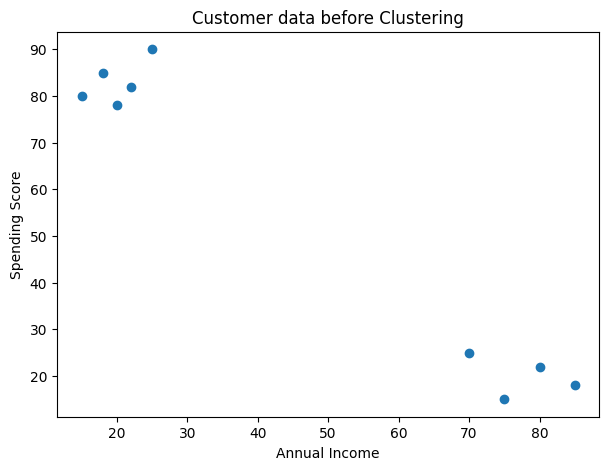

In [ ]:
plt.figure(figsize=(7,5))

plt.scatter(
    df["AnnualIncome"],
    df["SpendingScore"]
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer data before Clustering")


In [ ]:
x = df[["AnnualIncome","SpendingScore"]]
scaler = StandardScaler()
scaler.fit(x)
x_scaled = scaler.transform(x)

print(x_scaled.round(2))

[[-1.06  0.79]
 [-0.95  0.95]
 [-0.88  0.73]
 [-0.81  0.86]
 [-0.71  1.11]
 [ 0.85 -0.95]
 [ 1.02 -1.27]
 [ 1.19 -1.05]
 [ 1.36 -1.17]]


In [ ]:
kmeans = KMeans(
    n_clusters =2,
    random_state = 42,
    n_init = 10
)

kmeans.fit(x_scaled)

df["Cluster"] = kmeans.labels_
print(df)

   AnnualIncome  SpendingScore  Cluster
0            15             80        0
1            18             85        0
2            20             78        0
3            22             82        0
4            25             90        0
5            70             25        1
6            75             15        1
7            80             22        1
8            85             18        1


In [ ]:
centroids_scaled = kmeans.cluster_centers_

centroids_original = scaler.inverse_transform(centroids_scaled)

print("Cluster centroids in original units:")
print(centroids_original.round(2))


Cluster centroids in original units:
[[20.  83. ]
 [77.5 20. ]]


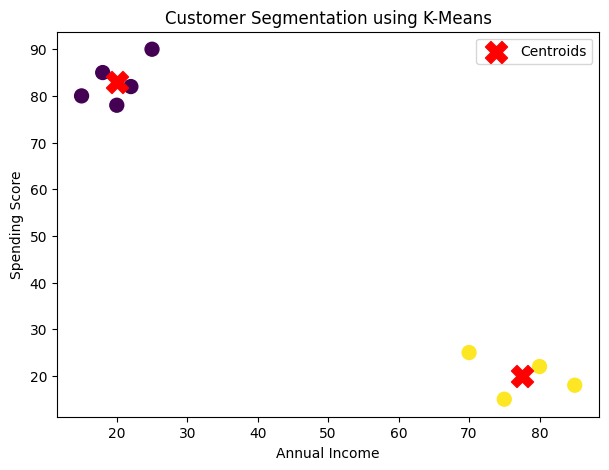

In [ ]:
plt.figure(figsize=(7, 5))

# Plot customers grouped by cluster
plt.scatter(
    df["AnnualIncome"],
    df["SpendingScore"],
    c=df["Cluster"],
    cmap="viridis",
    s=100
)

# Plot centroids in original units
plt.scatter(
    centroids_original[:, 0],
    centroids_original[:, 1],
    color="red",
    marker="X",
    s=250,
    label="Centroids"
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer Segmentation using K-Means")
plt.legend()
plt.show()